# Extended Data Figure 7: Invasion resistance and cooperation

One cross-norm panel and eight benefit-ratio planes compare one-step and selected multi-step architectures. Run from this notebook directory; supplied numerical data are loaded by default.

## Configuration

In [1]:
from pathlib import Path
from functools import lru_cache
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle, Patch
from scipy.optimize import brentq, root, root_scalar

ROOT = Path.cwd()
DATA = ROOT / 'data' / 'extended_data_figure7'
FIGURES = ROOT / 'figures' / 'extended_data_figure7'
DATA.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
RECOMPUTE = False

B_OVER_C = 5.0
E1 = E2 = .02
SECURITY_TOL = 1e-10
NORM_PARAMETERS = {'SC': (1.,0.), 'SH': (0.,0.), 'SJ': (0.,1.), 'SS': (1.,1.)}
PRESET = {'SC': (2,0), 'SH': (3,0), 'SJ': (4,3), 'SS': (1,2)}
NORM_NAMES = {'SC': 'Scoring', 'SH': 'Shunning', 'SJ': 'Stern Judging', 'SS': 'Simple Standing'}
MECHANISMS = ('one_step','multistep_full')
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':9,
                     'axes.linewidth':.7, 'pdf.fonttype':42, 'svg.fonttype':'none'})

## Resident and IID opportunistic-mutant equations

The highest strictly stable resident root is selected. The rational response is checked over the full deviation interval. The source tolerance is used at neutral boundaries.

In [2]:
def reputation_map(u, alpha, beta, k1, k2):
    u = np.asarray(u, dtype=float)
    v = 1.0 - u
    denominator = v**k1 + u**k2 - v**k1 * u**k2
    warning = sum((alpha * v)**m for m in range(1, k1 + 1))
    suspicious = sum(u**n * (1.0 - beta**n) for n in range(1, k2 + 1))
    numerator = u**(k2 + 1) * (1.0 + warning) + v**(k1 + 1) * suspicious
    return numerator / denominator


def reputation_map_derivative(u, alpha, beta, k1, k2):
    u = np.asarray(u, dtype=float)
    v = 1.0 - u
    warning = sum((alpha * v)**m for m in range(1, k1 + 1))
    warning_prime = sum(-m * alpha**m * v**(m - 1) for m in range(1, k1 + 1))
    suspicious = sum(u**n * (1.0 - beta**n) for n in range(1, k2 + 1))
    suspicious_prime = sum(n * u**(n - 1) * (1.0 - beta**n) for n in range(1, k2 + 1))
    denominator = v**k1 + u**k2 - v**k1 * u**k2
    denominator_prime = np.zeros_like(u)
    if k1:
        denominator_prime += -k1 * v**(k1 - 1) + k1 * v**(k1 - 1) * u**k2
    if k2:
        denominator_prime += k2 * u**(k2 - 1) - k2 * v**k1 * u**(k2 - 1)
    numerator = u**(k2 + 1) * (1.0 + warning) + v**(k1 + 1) * suspicious
    numerator_prime = (
        (k2 + 1) * u**k2 * (1.0 + warning)
        + u**(k2 + 1) * warning_prime
        - (k1 + 1) * v**k1 * suspicious
        + v**(k1 + 1) * suspicious_prime
    )
    return (numerator_prime * denominator - numerator * denominator_prime) / denominator**2


def assessment_terms(norm):
    p, q = NORM_PARAMETERS[norm]
    epsilon = (1.0 - E1) * (1.0 - E2) + E1 * E2
    p_cg = epsilon
    p_cb = p * (epsilon - E2) + q * (1.0 - epsilon - E2) + E2
    p_dg = E2
    p_db = q * (1.0 - 2.0 * E2) + E2
    return p_cg, p_cb, p_dg, p_db


def resident_phi(r, terms):
    p_cg, p_cb, p_dg, p_db = terms
    return r*r*p_cg + r*(1.0-r)*(p_cb+p_dg) + (1.0-r)**2*p_db


def resident_phi_prime(r, terms):
    p_cg, p_cb, p_dg, p_db = terms
    return 2.0*r*p_cg + (1.0-2.0*r)*(p_cb+p_dg) - 2.0*(1.0-r)*p_db


def resident_equilibria(norm,k1,k2,alpha,beta):
    terms = assessment_terms(norm)
    residual = lambda r: float(reputation_map(resident_phi(r,terms),alpha,beta,k1,k2)-r)
    derivative = lambda r: float(reputation_map_derivative(resident_phi(r,terms),alpha,beta,k1,k2))*resident_phi_prime(r,terms)-1
    degree = 2*(k1+k2+1)
    nodes = (1+np.cos(np.pi*(np.arange(degree+1)+.5)/(degree+1)))/2
    u = resident_phi(nodes,terms)
    v = 1-u
    den = v**k1+u**k2-v**k1*u**k2
    num = (u**(k2+1)*(1+sum((alpha*v)**m for m in range(1,k1+1)))
           +v**(k1+1)*sum(u**n*(1-beta**n) for n in range(1,k2+1)))
    polynomial = np.polynomial.Chebyshev.fit(nodes,num-nodes*den,degree,domain=[0,1])
    roots = []
    for z in polynomial.roots():
        if abs(z.imag)<1e-7 and -1e-10<=z.real<=1+1e-10:
            fit = root_scalar(residual,x0=float(np.clip(z.real,0,1)),fprime=derivative,method="newton",xtol=2e-15)
            r = float(fit.root)
            if 0<r<=1 and abs(residual(r))<5e-13 and not any(abs(r-other)<1e-10 for other in roots):
                roots.append(r)
    records = []
    cg,cb,dg,db = terms
    for r in sorted(roots):
        u = resident_phi(r,terms)
        fp = float(reputation_map_derivative(u,alpha,beta,k1,k2))
        flow = fp*resident_phi_prime(r,terms)-1
        records.append({"r_R":r,"Phi_R":u,"DeltaPhi":r*(cg-dg)+(1-r)*(cb-db),
                        "Rprime":fp,"flow_derivative":flow,"stable":flow < -1e-9,
                        "root_count":len(roots),"relative_residual":abs(residual(r))/r})
    return records


def resident_state(norm,k1,k2,alpha,beta,branch="high"):
    stable = [row for row in resident_equilibria(norm,k1,k2,alpha,beta) if row["stable"]]
    assert stable,(norm,k1,k2,alpha,beta)
    selected = (max if branch=="high" else min)(stable,key=lambda row:row["r_R"])
    assert selected["relative_residual"]<2e-11
    return selected



def prepare_case(norm,mechanism="multistep_full",alpha_override=1.,branch="high",arch_override=None,beta_override=1.):
    arch = (1,1) if mechanism=="one_step" else PRESET[norm]
    if arch_override is not None:
        arch = tuple(arch_override)
    alpha,beta = float(alpha_override),float(beta_override)
    state = resident_state(norm,*arch,alpha,beta,branch)
    return {**state,"norm":norm,"mechanism":mechanism,"k1":arch[0],"k2":arch[1],
            "alpha":alpha,"beta":beta,"Fprime":state["Rprime"]}


def rational_parts(case):
    P = np.polynomial.Polynomial
    r, u0, contrast = (case['r_R'], case['Phi_R'], case['DeltaPhi'])
    k1, k2 = (int(case['k1']), int(case['k2']))
    alpha, beta = (case['alpha'], case['beta'])
    u = P([u0, -r * contrast])
    v = 1 - u
    den = v ** k1 + u ** k2 - v ** k1 * u ** k2
    num = u ** (k2 + 1) * (1 + sum(((alpha * v) ** m for m in range(1, k1 + 1)))) + v ** (k1 + 1) * sum((u ** n * (1 - beta ** n) for n in range(1, k2 + 1)))
    loss = float(num(0) / den(0)) * den - num
    coefficients = np.r_[loss.coef[1:], 0.0] / r
    coefficients[0] = float(den(0)) * contrast * case['Fprime']
    return (P(coefficients), den)

def normalized_inertial_rational(case, benefit=None):
    loss, den = rational_parts(case)
    return (den - (B_OVER_C if benefit is None else benefit) * loss, den)

def real_unit_roots(polynomial):
    return sorted((float(z.real) for z in polynomial.roots() if abs(z.imag) < 1e-07 and 1e-08 < z.real < 1))

def polynomial_intervals(score, den):
    roots = real_unit_roots(score)
    bounds = [0.0, *roots, 1.0]
    intervals = [(a, b) for a, b in zip(bounds[:-1], bounds[1:]) if score((a + b) / 2) / den((a + b) / 2) > 1e-11]
    return (roots, intervals)

def response_minimum(case):
    loss, den = rational_parts(case)
    candidates = [0.0, 1.0, *real_unit_roots(loss.deriv() * den - loss * den.deriv())]
    responses = np.array([loss(d) / den(d) for d in candidates])
    j = int(np.argmin(responses))
    return (float(responses[j]), candidates[j])

@lru_cache(None)
def find_folds(norm, arch, beta=1.0):
    terms = assessment_terms(norm)

    def equations(pair):
        r, a = pair
        u = resident_phi(r, terms)
        return [float(reputation_map(u, a, beta, *arch)) - r, float(reputation_map_derivative(u, a, beta, *arch)) * resident_phi_prime(r, terms) - 1]
    found = []
    for a0 in np.linspace(0.05, 0.95, 8):
        for r0 in np.linspace(0.05, 0.95, 9):
            with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
                fit = root(equations, [r0, a0], tol=1e-11)
            if fit.success and np.all((fit.x > 0) & (fit.x < 1)) and (np.max(abs(np.asarray(equations(fit.x)))) < 1e-09) and (not any((np.linalg.norm(fit.x - other) < 1e-06 for other in found))):
                found.append(fit.x)
    return sorted([(float(r), float(a)) for r, a in found], key=lambda pair: pair[1])

def security_condition(case,benefit=B_OVER_C):
    return 1-benefit*response_minimum(case)[0]


def boundary_intervals(norm,arch,beta,mechanism,benefit,grid,cases,responses,folds):
    # Reuse the resident scan: benefit changes invasion, not cooperation.
    values = 1-benefit*responses
    case_at = lambda a: prepare_case(norm,mechanism,alpha_override=a,arch_override=arch,beta_override=beta)
    boundaries = []
    for j in np.flatnonzero(values[:-1]*values[1:]<0):
        left,right = grid[j:j+2]
        crossed = [(r,a) for r,a in folds if left<a<right]
        if crossed and abs(cases[j+1]["r_R"]-cases[j]["r_R"])>.15:
            r,a = crossed[0]
            reason,included = "fold",False
        else:
            a = brentq(lambda a:security_condition(case_at(a),benefit),left,right,xtol=2e-13)
            case = case_at(a)
            r = case["r_R"]
            reason = "local_slope" if response_minimum(case)[1]<1e-8 else "global_delta"
            included = True
        boundaries.append(dict(alpha=a,r_R=r,reason=reason,included=included))
    limits = [dict(alpha=0.,r_R=cases[0]["r_R"],reason="domain",included=True),*boundaries,
              dict(alpha=1.,r_R=cases[-1]["r_R"],reason="domain",included=True)]
    intervals = []
    for lo,hi in zip(limits[:-1],limits[1:]):
        if security_condition(case_at((lo["alpha"]+hi["alpha"])/2),benefit)<=SECURITY_TOL:
            intervals.append(dict(norm=norm,mechanism=mechanism,k1=arch[0],k2=arch[1],beta=beta,b_over_c=benefit,
                alpha_lower=lo["alpha"],alpha_upper=hi["alpha"],r_lower=lo["r_R"],r_upper=hi["r_R"],
                lower_reason=lo["reason"],upper_reason=hi["reason"],lower_included=lo["included"],upper_included=hi["included"]))
    assert len(intervals)<=1,(norm,beta,benefit,intervals)
    return intervals


def scan_alpha(norm,arch,beta=1.,mechanism="multistep_full",count=601):
    folds = find_folds(norm,tuple(arch),float(beta))
    grid = np.unique(np.r_[np.linspace(0,1,count),[a+t for r,a in folds for t in (-1e-6,1e-6)],.8])
    cases = [prepare_case(norm,mechanism,alpha_override=a,arch_override=arch,beta_override=beta) for a in grid]
    responses = np.array([response_minimum(case)[0] for case in cases])
    return grid,cases,responses,folds


def recompute_displayed_data():
    profile_rows, interval_rows, boundary_rows, reference_rows = [], [], [], []
    benefits = np.linspace(2.,8.,161)
    for norm, preset in PRESET.items():
        for mechanism in MECHANISMS:
            depth = (1,1) if mechanism == 'one_step' else preset
            grid,cases,responses,folds = scan_alpha(norm,depth,mechanism=mechanism)
            intervals = boundary_intervals(norm,depth,1.,mechanism,5.,grid,cases,responses,folds)
            if len(intervals) != 1:
                raise RuntimeError(f'Expected one reference interval for {norm}, {mechanism}.')
            interval_rows.extend(intervals)
            for alpha,case,response in zip(grid,cases,responses):
                profile_rows.append(dict(norm=norm,mechanism=mechanism,alpha=alpha,
                    r_R=case['r_R'],iid_secure=1-5*response<=SECURITY_TOL))
            lower,upper = [],[]
            for benefit in benefits:
                rows = boundary_intervals(norm,depth,1.,mechanism,benefit,grid,cases,responses,folds)
                if rows:
                    boundary_rows.extend({**row,'has_secure_interval':True} for row in rows)
                    lower.append(rows[0]['alpha_lower']); upper.append(rows[0]['alpha_upper'])
                else:
                    boundary_rows.append(dict(norm=norm,mechanism=mechanism,k1=depth[0],k2=depth[1],
                        beta=1.,b_over_c=benefit,has_secure_interval=False,alpha_lower=np.nan,alpha_upper=np.nan))
                    lower.append(np.nan); upper.append(np.nan)
            prefix = 'onestep' if mechanism=='one_step' else 'd'
            np.savez_compressed(DATA/f'{prefix}_{norm}_shared_fields.npz',alpha=grid,b_over_c=benefits,
                r_R=np.array([case['r_R'] for case in cases]),
                alpha_lower=np.asarray(lower),alpha_upper=np.asarray(upper))
            case = prepare_case(norm,mechanism,alpha_override=.8)
            reference_rows.append(dict(norm=norm,mechanism=mechanism,alpha=.8,b_over_c=5.,
                r_R=case['r_R'],iid_secure=security_condition(case,5.)<=SECURITY_TOL))
            print(f'Recomputed {norm}, {mechanism}.',flush=True)
    pd.DataFrame(profile_rows).to_csv(DATA/'c_complete_cooperation_profiles.csv',index=False)
    pd.DataFrame(interval_rows).to_csv(DATA/'c_secure_alpha_intervals.csv',index=False)
    pd.DataFrame(boundary_rows).to_csv(DATA/'benefit_alpha_intervals_both_mechanisms.csv',index=False)
    pd.DataFrame(reference_rows).to_csv(DATA/'reference_point_08_5.csv',index=False)
    config['current_data_origin']='Freshly recomputed displayed fields, without the optional delta_c background.'
    config.pop('files',None)
    (DATA/'input_config.json').write_text(json.dumps(config,indent=2)+'\n')


## Numerical data

Set `RECOMPUTE=True` to recalculate the displayed alpha and benefit-ratio scans; this can be expensive and replaces the supplied tables. Fold endpoints are excluded. Saved data and the original independent validation table are external.

In [3]:
config_path = DATA/'input_config.json'
if not config_path.is_file():
    raise FileNotFoundError('Supply data/extended_data_figure7 before running this notebook.')
config = json.loads(config_path.read_text())
assert config['baseline']==dict(beta=1.,e1=E1,e2=E2,bar_b_over_c=B_OVER_C)
assert config['benefit_range']==[2.,8.] and config['benefit_points']==161
assert config['security_tolerance']==SECURITY_TOL
if RECOMPUTE:
    recompute_displayed_data()

profiles = pd.read_csv(DATA/'c_complete_cooperation_profiles.csv')
intervals = pd.read_csv(DATA/'c_secure_alpha_intervals.csv')
boundaries = pd.read_csv(DATA/'benefit_alpha_intervals_both_mechanisms.csv')
references = pd.read_csv(DATA/'reference_point_08_5.csv')
assert len(intervals)==len(references)==8 and len(boundaries)==8*161
maps = {}
max_residual = 0.
max_flow_slope = -np.inf
for norm in PRESET:
    for mechanism in MECHANISMS:
        prefix = 'onestep' if mechanism=='one_step' else 'd'
        path = DATA/f'{prefix}_{norm}_shared_fields.npz'
        with np.load(path,allow_pickle=False) as saved:
            maps[norm,mechanism] = {key:saved[key] for key in saved.files}
        a = maps[norm,mechanism]['alpha']
        r = maps[norm,mechanism]['r_R']
        benefits = maps[norm,mechanism]['b_over_c']
        lo = maps[norm,mechanism]['alpha_lower']
        hi = maps[norm,mechanism]['alpha_upper']
        assert len(a)>=601 and np.all(np.diff(a)>0)
        assert a[0]==0. and a[-1]==1. and r.shape==a.shape
        np.testing.assert_allclose(benefits,np.linspace(2.,8.,161),atol=1e-14,rtol=0)
        assert lo.shape==hi.shape==benefits.shape
        part = profiles.loc[profiles.norm.eq(norm)&profiles.mechanism.eq(mechanism)].sort_values('alpha')
        np.testing.assert_allclose(part.alpha,a,atol=2e-16,rtol=0)
        np.testing.assert_allclose(part.r_R,r,atol=2e-15,rtol=0)
        stored_boundaries = boundaries.loc[boundaries.norm.eq(norm)&boundaries.mechanism.eq(mechanism)].sort_values('b_over_c')
        np.testing.assert_allclose(stored_boundaries.alpha_lower,lo,atol=2e-13,rtol=0,equal_nan=True)
        np.testing.assert_allclose(stored_boundaries.alpha_upper,hi,atol=2e-13,rtol=0,equal_nan=True)
        assert len(intervals.loc[intervals.norm.eq(norm)&intervals.mechanism.eq(mechanism)])==1
        depth = (1,1) if mechanism=='one_step' else PRESET[norm]
        terms = assessment_terms(norm)
        u = resident_phi(r,terms)
        residual = np.abs(reputation_map(u,a,1.,*depth)-r)
        slope = reputation_map_derivative(u,a,1.,*depth)*resident_phi_prime(r,terms)-1
        max_residual = max(max_residual,float(residual.max()))
        max_flow_slope = max(max_flow_slope,float(slope.max()))
        assert np.all(residual<5e-13) and np.all(slope < -1e-9)
        if 'delta_c' in maps[norm,mechanism]:
            row = np.flatnonzero(benefits==5.).item()
            np.testing.assert_array_equal(part.iid_secure.to_numpy(),maps[norm,mechanism]['delta_c'][row]==0.)
        case = prepare_case(norm,mechanism,alpha_override=.8)
        ref = references.loc[references.norm.eq(norm)&references.mechanism.eq(mechanism)].iloc[0]
        assert abs(case['r_R']-ref.r_R)<2e-11
        assert bool(security_condition(case,5.)<=SECURITY_TOL)==bool(ref.iid_secure)
print(f'Loaded {len(profiles)} strictly stable resident samples; max residual {max_residual:.2e}.')

Loaded 4822 strictly stable resident samples; max residual 7.22e-16.


## Panels

Green denotes resident intended cooperation. Black outlines show security against the entire IID O-DISC family, not a cooperation threshold. Open circles on strips mark excluded fold endpoints; circles on maps mark the common reference point (0.8, 5).

In [4]:
COOP_CMAP = LinearSegmentedColormap.from_list('cooperation',['#F5F7F1','#ACCCB8','#447C67'])
COLOR_NORM = Normalize(0,1)
MECH_LABEL = {'one_step':'One-step','multistep_full':'Multi-step'}

def draw_cross_norm(ax):
    for row,norm in enumerate(PRESET):
        for offset,mechanism in ((-.20,'one_step'),(.20,'multistep_full')):
            y = row+offset
            part = profiles.loc[profiles.norm.eq(norm)&profiles.mechanism.eq(mechanism)].sort_values('alpha')
            a,r = part.alpha.to_numpy(),part.r_R.to_numpy()
            edges = np.r_[0.,(a[:-1]+a[1:])/2.,1.]
            ax.pcolormesh(edges,[y-.14,y+.14],r[None,:],cmap=COOP_CMAP,
                          norm=COLOR_NORM,shading='flat',rasterized=True)
            interval = intervals.loc[intervals.norm.eq(norm)&intervals.mechanism.eq(mechanism)].iloc[0]
            ax.add_patch(Rectangle((interval.alpha_lower,y-.14),
                interval.alpha_upper-interval.alpha_lower,.28,fill=False,edgecolor='.1',lw=.95,zorder=4))
            if not bool(interval.lower_included):
                ax.plot(interval.alpha_lower,y,'o',ms=3.5,mec='.1',mfc='white',mew=.7,zorder=5)
            if not bool(interval.upper_included):
                ax.plot(interval.alpha_upper,y,'o',ms=3.5,mec='.1',mfc='white',mew=.7,zorder=5)
            ax.text(1.015,y,MECH_LABEL[mechanism],transform=ax.get_yaxis_transform(),
                    ha='left',va='center',fontsize=7.5,clip_on=False)
    ax.set(xlim=(0,1),ylim=(3.6,-.6),xlabel=r'Readout parameter $\alpha$')
    ax.set_xticks(np.linspace(0,1,6))
    ax.set_yticks(range(4),[f'{norm}  ({PRESET[norm][0]},{PRESET[norm][1]})' for norm in PRESET])
    ax.spines[['top','right','left']].set_visible(False)
    ax.tick_params(axis='y',length=0)

def draw_map(ax,norm,mechanism):
    data = maps[norm,mechanism]
    colors = np.broadcast_to(data['r_R'],(len(data['b_over_c']),len(data['alpha'])))
    ax.pcolormesh(data['alpha'],data['b_over_c'],colors,cmap=COOP_CMAP,norm=COLOR_NORM,
                  shading='nearest',rasterized=True)
    for key in ('alpha_lower','alpha_upper'):
        ax.plot(data[key],data['b_over_c'],color='.1',lw=1.1,zorder=4)
    ax.scatter([.8],[5],s=24,facecolors='white',edgecolors='.1',lw=.8,zorder=6)
    ax.set(xlim=(0,1),ylim=(2,8),xticks=[0,.5,1],yticks=[2,5,8],
           xlabel=r'Readout parameter $\alpha$',ylabel=r'Benefit-to-cost ratio $b/c$')
    ax.spines[['top','right']].set_visible(False)

def add_colorbar(fig,rect):
    cax = fig.add_axes(rect)
    bar = fig.colorbar(plt.cm.ScalarMappable(norm=COLOR_NORM,cmap=COOP_CMAP),cax=cax,ticks=[0,.5,1])
    bar.set_label(r'Intended cooperation $r_R$')
    bar.outline.set_linewidth(.6)

def save_figure(fig,name):
    for ext in ('pdf','svg'):
        fig.savefig(FIGURES/f'{name}.{ext}',bbox_inches='tight',pad_inches=.04)


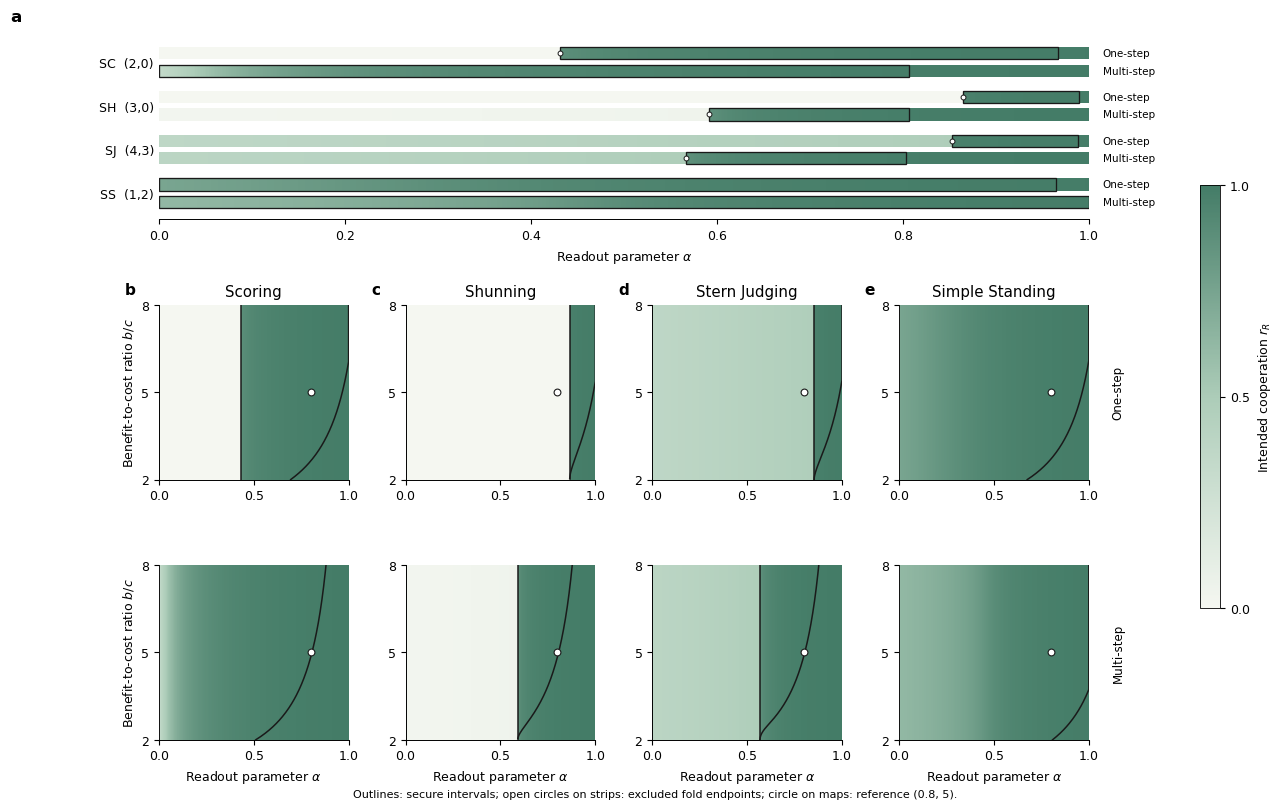

Saved nine panels and one combined figure in PDF and SVG.


In [5]:
fig,ax=plt.subplots(figsize=(9.2,4.3))
fig.subplots_adjust(left=.18,right=.76,bottom=.18,top=.88)
draw_cross_norm(ax)
add_colorbar(fig,[.90,.25,.018,.50])
fig.text(.17,.95,'Black outlines: secure intervals; open circles: excluded fold endpoints',fontsize=8)
save_figure(fig,'panel_a_cross_norm')
plt.close(fig)

for letter,norm in zip('bcde',PRESET):
    for mechanism in MECHANISMS:
        fig,ax=plt.subplots(figsize=(4.7,4.0))
        fig.subplots_adjust(left=.16,right=.73,bottom=.22,top=.88)
        draw_map(ax,norm,mechanism)
        depth=(1,1) if mechanism=='one_step' else PRESET[norm]
        ax.set_title(f'{NORM_NAMES[norm]}: {MECH_LABEL[mechanism]} ({depth[0]},{depth[1]})')
        add_colorbar(fig,[.79,.26,.025,.52])
        fig.text(.16,.045,'Black curves: secure interval; circle: (0.8, 5).',fontsize=7.7)
        save_figure(fig,f'panel_{letter}_{norm}_{mechanism}')
        plt.close(fig)

fig = plt.figure(figsize=(12.4,8.8))
grid = fig.add_gridspec(3,4,left=.09,right=.84,bottom=.12,top=.92,
                        hspace=.48,wspace=.30,height_ratios=[1.05,1,1])
ax=fig.add_subplot(grid[0,:])
draw_cross_norm(ax)
ax.text(-.16,1.08,'a',transform=ax.transAxes,fontweight='bold',fontsize=12)
for row,mechanism in enumerate(MECHANISMS,1):
    for col,(letter,norm) in enumerate(zip('bcde',PRESET)):
        ax=fig.add_subplot(grid[row,col])
        draw_map(ax,norm,mechanism)
        if row==1:
            ax.set_title(NORM_NAMES[norm])
            ax.text(-.18,1.06,letter,transform=ax.transAxes,fontweight='bold',fontsize=11)
            ax.set_xlabel('')
        if col: ax.set_ylabel('')
        if col==3:
            ax.text(1.12,.5,MECH_LABEL[mechanism],transform=ax.transAxes,
                    rotation=90,va='center',ha='left',fontsize=8.5,clip_on=False)
add_colorbar(fig,[.93,.27,.016,.48])
fig.text(.49,.055,'Outlines: secure intervals; open circles on strips: excluded fold endpoints; circle on maps: reference (0.8, 5).',
         ha='center',fontsize=8)
save_figure(fig,'Extended_Data_Figure7_combined')
plt.show()
plt.close(fig)
assert len(list(FIGURES.glob('*.pdf')))==len(list(FIGURES.glob('*.svg')))==10
print('Saved nine panels and one combined figure in PDF and SVG.')